# Panel 4 and 5

This notebook contains the majority of the images for the fourth and fifth panels of the paper, including the likelihood scans, and GP parameter fits. Data is imported from the fitted GPs, and from the saved likelihood scans.

In [1]:
# Autoreloading of modules and files without restarting notebook.
%reload_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
from pathlib import Path
from copy import deepcopy
from math import log10, floor
import matplotlib.pyplot as plt

from rvm_analysis.colours import get_cell_colour, generate_color_spectrum
from rvm_analysis.save_tools import save_in_folder
from rvm_analysis.plotting import plot_rainclouds

#! Force the backend back to matplotlib inline (after importing viziphant).
%matplotlib inline
print(plt.get_backend())

C:\Users\carla\AppData\Local\Temp\ipykernel_30368\7070265.py:7: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


module://matplotlib_inline.backend_inline


These paths are required to have the GP fit and likelihood scan output results in order to run.

In [2]:
gaussian_process_param_save_directory = Path("./results/sim_neuts/")
image_save_path: Path = Path("./Sim_neuts_Images")
hyperparameter_dataframe_name = "model_summary_sim_neuts.csv"

In [3]:
fontsize = 7
plt.rcParams['savefig.pad_inches'] = 0
plt.rcParams["xtick.labelsize"] = fontsize
plt.rcParams["ytick.labelsize"] = fontsize

## Plotting GP parameter fits

      model_id  cell_name  id  lengthscale  period_length  outputscale  \
0    NEUTRAL_0   periodic   0     0.750734     306.814668     3.419456   
1    NEUTRAL_1   periodic   1     0.734927     308.083037     6.891235   
2    NEUTRAL_2   periodic   2     0.745058     301.756670     4.925387   
3    NEUTRAL_3   periodic   3     0.751831     296.428887     4.161714   
4    NEUTRAL_4   periodic   4     0.744522     303.293348     5.463701   
..         ...        ...  ..          ...            ...          ...   
75  NEUTRAL_75  aperiodic  75     0.736718     295.520047     0.667821   
76  NEUTRAL_76  aperiodic  76     0.743218     289.061510     0.189837   
77  NEUTRAL_77  aperiodic  77     0.743778     298.489360     0.053475   
78  NEUTRAL_78  aperiodic  78     0.741237     304.352910     0.302565   
79  NEUTRAL_79  aperiodic  79     0.733995     314.178410     1.008558   

           w  noise_prob  Train Model ELPD  Train Mean Model ELPD  \
0   0.763269        0.01       -556.387965

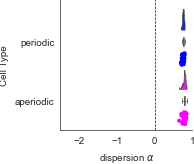

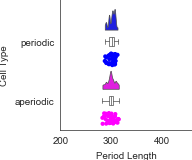

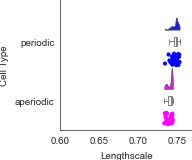

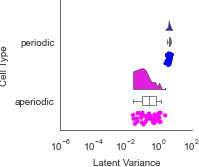

c:\Users\carla\Documents\Cambridge\PhD\Paper_1\Submission\Publication_Code\Multi-timescale-Rhythmic-Dynamics-in-RVM-neurons\env\lib\site-packages\seaborn\categorical.py:253: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Users\carla\Documents\Cambridge\PhD\Paper_1\Submission\Publication_Code\Multi-timescale-Rhythmic-Dynamics-in-RVM-neurons\env\lib\site-packages\seaborn\categorical.py:253: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Users\carla\Documents\Cambridge\PhD\Paper_1\Submission\Publication_Code\Multi-timescale-Rhythmic-Dy

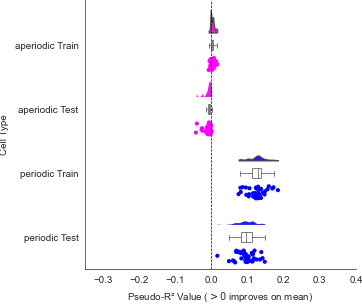

In [7]:
custom_palette={
    # "ON Train": get_cell_colour(names="ON"),
    # "ON Test": get_cell_colour(names="ON"),
    # "OFF Train": get_cell_colour(names="OFF"),
    # "OFF Test": get_cell_colour(names="OFF"),
    # "NEUTRAL Train": get_cell_colour(names="NEUTRAL"),
    # "NEUTRAL Test": get_cell_colour(names="NEUTRAL"),
    "aperiodic Train": "magenta",
    "aperiodic Test": "magenta",
    "periodic Train": "blue",
    "periodic Test": "blue",
}
custom_palette_w={
    # "ON": get_cell_colour(names="ON"),
    # "OFF": get_cell_colour(names="OFF"),
    # "NEUTRAL": get_cell_colour(names="NEUTRAL"),
    "aperiodic": "magenta",
    "periodic": "blue"
}

def plot_kernel_results_from_path(data_path: Path,kernel_name: str, dataframe_name: str, save_path: Path):
    """
    Plots the parameter fits of the Poisson GP kernel,
    taking a path to the directory where the saved parameters are located,
    and the name of the kernel (model shorthand) for saving only.
    """
    with open(os.path.join(data_path,dataframe_name)) as data_csv:
        df = pd.read_csv(data_csv)

        df["cell_name"] = df["model_id"].str.extract(r"NEUTRAL_(\d+)")[0].astype(int).apply(
            lambda x: "aperiodic" if x >= 40 else "periodic"
        )
        print(df)

        size = 1.7
        fig, ax = plt.subplots(figsize=(size,size))
        plot_rainclouds("",'w',df,xlim=[-2.5,1.0],move=0.3,
                        custom_palette=custom_palette_w, ax=ax, xlabel="dispersion $\\alpha$")
        save_in_folder(f"{kernel_name}_w",basePath="./Images",svg=True,save=True)


        fig, ax = plt.subplots(figsize=(size,size))
        plot_rainclouds(data_csv,'period_length',df,xlim=[200,460.0],move=0.3,
                        custom_palette=custom_palette_w, ax=ax, xlabel="Period Length")
        save_in_folder(f"{kernel_name}_period_length",basePath="./Images",svg=True,save=True)

        fig, ax = plt.subplots(figsize=(size,size))
        plot_rainclouds(data_csv,'lengthscale',df,xlim=[0.6,0.77],move=0.3,
                        custom_palette=custom_palette_w, ax=ax, xlabel="Lengthscale")
        save_in_folder(f"{kernel_name}_lengthscale",basePath="./Images",svg=True,save=True)

        fig, ax = plt.subplots(figsize=(size,size))
        plot_rainclouds(data_csv,'outputscale',df,xlim=[1e-6,120.0],move=0.3,
                        custom_palette=custom_palette_w, ax=ax, xlabel="Latent Variance")
        ax.set_xscale("log")
        save_in_folder(f"{kernel_name}_outputscale",basePath="./Images",svg=True,save=True)


    # Load the data
    df = pd.read_csv(os.path.join(data_path, "model_summary_sim_neuts.csv"))
    df["cell_name"] = df["model_id"].str.extract(r"NEUTRAL_(\d+)")[0].astype(int).apply(
        lambda x: "aperiodic" if x >= 40 else "periodic"
    )
    

    train: pd.DataFrame = df[['cell_name', 'Train Pseudo-R2']].copy() #type: ignore
    train['cell_name'] = train['cell_name'] + ' Train'
    train = train.rename(columns={'Train Pseudo-R2': 'Pseudo-R2'}) #type: ignore

    test: pd.DataFrame = df[['cell_name', 'Test Pseudo-R2']].copy() #type: ignore
    test['cell_name'] = test['cell_name'] + ' Test'
    test = test.rename(columns={'Test Pseudo-R2': 'Pseudo-R2'})# type: ignore


    # Combine into one long-format DataFrame
    df_combined: pd.DataFrame = pd.concat([test, train], ignore_index=True)
    df_combined['cell_name'] = pd.Categorical(df_combined['cell_name'],categories=custom_palette.keys(),ordered=False)
    df_sorted=df_combined
    df_sorted = df_combined.sort_values('cell_name')
    # print(df_sorted)
    # Plot
    f, ax = plt.subplots(figsize=(3.5, 3.5))
    plot_rainclouds(None, 'Pseudo-R2', df_sorted, xlim=[-0.35, 0.4], ax=ax,
                    custom_palette=custom_palette,move=0.3,cloud_linewidths = [0.8,0.0,0.8,0.0,0.8,0.0]
    )

    # laeset_position((-0.2,0.5))
    # plt.tight_layout(h_pad=0.6)
    save_in_folder(f"{kernel_name}_r2_plot",save_path,svg=True,save=True)

plot_kernel_results_from_path(kernel_name="periodic",
                              data_path = gaussian_process_param_save_directory, dataframe_name=hyperparameter_dataframe_name,save_path=image_save_path)


## Printing GP hyperparameter value statistics

In [8]:
def get_param(param_name,data_path: Path,dataframe_name: str):
        """ Gets the mean, standard deviation, and count of a parameter. """
        with open(data_path / dataframe_name) as data_csv:
                df = pd.read_csv(data_csv)

                print(df.groupby('cell_name')[param_name].mean())
                print(df.groupby('cell_name')[param_name].std())
                print(df.groupby('cell_name')[param_name].count())

In [9]:
get_param("lengthscale",
        data_path= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
        )

get_param("period_length",
        data_path= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
        )

# This is alpha
get_param("w",
        data_path= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
        )

get_param("outputscale",
        data_path= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
        )

cell_name
NEUTRAL    0.744716
Name: lengthscale, dtype: float64
cell_name
NEUTRAL    0.005052
Name: lengthscale, dtype: float64
cell_name
NEUTRAL    80
Name: lengthscale, dtype: int64
cell_name
NEUTRAL    300.292527
Name: period_length, dtype: float64
cell_name
NEUTRAL    7.42943
Name: period_length, dtype: float64
cell_name
NEUTRAL    80
Name: period_length, dtype: int64
cell_name
NEUTRAL    0.771935
Name: w, dtype: float64
cell_name
NEUTRAL    0.034331
Name: w, dtype: float64
cell_name
NEUTRAL    80
Name: w, dtype: int64
cell_name
NEUTRAL    2.578031
Name: outputscale, dtype: float64
cell_name
NEUTRAL    2.196954
Name: outputscale, dtype: float64
cell_name
NEUTRAL    80
Name: outputscale, dtype: int64


In [10]:
params = ["period_length", "w", "outputscale","lengthscale", ]

def format_sigfig_no_sci(x, sig=2):
    """
    Formats a number to `sig` significant figures without scientific notation.
    """
    if pd.isna(x):
        return ""

    if x == 0:
        return "0"

    # number of digits before decimal
    power = floor(log10(abs(x)))

    # digits after decimal
    decimals = sig - power - 1
    decimals = max(decimals, 0)
    fmt = "{:." + str(decimals) + "f}"
    out = fmt.format(x)

    out = out.rstrip("0").rstrip(".")
    return out

def make_latex_table(base_save_dir: Path, dataframe_name: str, output_tex_path="param_table.tex"):
    """
    Makes a latex table with the output parameter values in it.
    """
    df = pd.read_csv(os.path.join(base_save_dir, dataframe_name))

    rows = []
    cell_names = df['cell_name'].unique()

    for cell in cell_names:
        row = [cell]
        cell_df = df[df['cell_name'] == cell]

        for p in params:
            mean_val = cell_df[p].mean()
            std_val  = cell_df[p].std()

            mean_f = format_sigfig_no_sci(mean_val, 2)
            std_f  = format_sigfig_no_sci(std_val, 2)

            row.append(f"{mean_f} \\pm {std_f}")

        rows.append(row)

    # Build the table
    header = "Cell & " + " & ".join(params) + " \\\\"
    latex = [
        "\\begin{table}[h!]",
        "\\centering",
        "\\begin{tabular}{l" + "c" * len(params) + "}",
        "\\hline",
        header,
        "\\hline"
    ]

    for r in rows:
        latex.append(" & ".join(r) + " \\\\")

    latex += [
        "\\hline",
        "\\end{tabular}",
        "\\caption{Parameter means $\\pm$ std (2 significant figures, no scientific notation).}",
        "\\end{table}"
    ]

    latex_text = "\n".join(latex)

    with open(output_tex_path, "w") as f:
        f.write(latex_text)

    print(f"LaTeX table written to {output_tex_path}")


make_latex_table(base_save_dir= gaussian_process_param_save_directory, dataframe_name = hyperparameter_dataframe_name
)


LaTeX table written to param_table.tex
